# 2026 full forecast: House and Senate

**This is the production entry point.** It runs both chambers, applies your margin adjustments, rates every race, runs the generic-ballot scenarios, and writes the submission (`data/processed/full congress track template.csv`).

| step | code |
|---|---|
| House: Stage 1 → race handling → Stage 2 (H0) → track rows | `src/house/forecast.py` |
| Senate: Stage 1 → blend (weights set below) → Monte Carlo (S-M0) → track rows | `src/senate/forecast.py` |
| Margin adjustments and generic-ballot shifts | `src/congress/adjustments.py` |
| Ratings, race tables, chamber summaries | `src/congress/report.py` |
| Merge, validate, write the submission | `data-processing/congress_track.py` |

- **What you edit:** the settings cell below (Senate blend weights, rating thresholds, generic-ballot shifts) and `data/reference/margin_adjustments_2026.csv` (section 1).
- **Calibration lives elsewhere:** `notebooks/house/stage2/02_monte_carlo.ipynb` and `notebooks/senate/stage2/03_monte_carlo.ipynb` hold the calibration and backtests. Their track files are the model's own rows, which the model runs here must reproduce (section 2).
- **Order of operations:** each chamber's model forecast; then the adjustments, added to race margins before the Monte Carlo; then the generic-ballot shifts, run on the adjusted forecast. The submission is the adjusted forecast at the actual generic ballot.
- **Kalshi (section 9):** the Kalshi portfolio is sized on the submission from cached prices, and its profit is priced in every simulation and every generic-ballot scenario, with the worst case reported.
- **Deterministic:** every run uses its chamber's fixed seed, and probabilities are written to 6 decimals, so a rerun on the same inputs writes identical files (checked in section 8).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "data-processing")]
import congress_track
from scipy import stats

from congress import adjustments, predictions, report
from house import forecast as house_forecast
from house import simulation
from house.regression.schema import KEY
from kalshi import odds, optimizer
from kalshi import run as kalshi_run
from polymarket import odds as polymarket_odds
from scenarios import generic_ballot
from senate import forecast as senate_forecast
from senate import stage2
from senate.simulation import chamber

pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)

## Settings

- **Senate blend weights:** fundamentals / polls / experts, one set for races with polls and one for races without. The production values are `senate.stage2.WEIGHTS`. Each case must sum to 1, and the no-polls case can't weight polls.
  - The Senate error SDs are re-estimated from the 2016–2024 out-of-sample residuals of the blend with these same weights. So changing the weights changes both the centers and the spread around them.
- **Rating thresholds:** the predicted side's win probability below which a race is Toss-up, Lean or Likely; Safe otherwise. This is a reporting convention only: nothing upstream reads it.
- **Generic-ballot shifts:** points added to 2026's generic ballot (D+8.7). Negative is toward Republicans.
- **Polymarket:** `POLYMARKET_REFRESH = True` pulls Polymarket's current prices from the public API on every run (and caches the pull in `data/raw/polymarket/`); `False` reuses the latest cached pull. Section 10.

In [2]:
SENATE_WEIGHTS = {
    "polling":    {"fundamentals": 0.37, "polling": 0.54, "experts": 0.09},
    "no_polling": {"fundamentals": 0.65, "polling": 0.00, "experts": 0.35},
}
RATING_THRESHOLDS = {"Toss-up": 0.60, "Lean": 0.75, "Likely": 0.95}
GB_SHIFTS = {"R+4": -4.0, "R+2": -2.0, "D+2": 2.0, "D+4": 4.0}  # the generic ballot off by this much
ADJUSTMENTS_PATH = adjustments.MARGIN_ADJUSTMENTS_PATH  # data/reference/margin_adjustments_2026.csv
WRITE_SUBMISSION = True
POLYMARKET_REFRESH = True  # section 10: live Polymarket prices now (False: the latest cached pull)
FINAL_PREDS_PATH = ROOT / "predictions/final_preds.csv"

stage2.check_weights(SENATE_WEIGHTS)
CUSTOM_SENATE_WEIGHTS = SENATE_WEIGHTS != stage2.WEIGHTS
print("Senate weights:", "CUSTOM" if CUSTOM_SENATE_WEIGHTS else "production (senate.stage2.WEIGHTS)")

Senate weights: production (senate.stage2.WEIGHTS)


In [3]:
# The production Stage 2 settings, from the two forecast modules (change them there, not here)
pd.DataFrame({
    "House": {"Stage 1": house_forecast.CONFIG.name, "fallback": house_forecast.FALLBACK_CONFIG.name,
              "error model": f"H0, t(nu={house_forecast.NU})", "simulations": house_forecast.N_SIMS,
              "seed": f"[{house_forecast.SEED}, 2026]"},
    "Senate": {"Stage 1": senate_forecast.CONFIG.name, "fallback": "",
               "error model": f"{senate_forecast.MODEL}, t(nu=5)", "simulations": senate_forecast.N_SIMS,
               "seed": senate_forecast.SEED},
})

,House,Senate
Stage 1,house_ensemble_ab_85_15,senate_s1
fallback,house_model_a,
error model,"H0, t(nu=5)","S-M0, t(nu=5)"
simulations,40000,40000
seed,"[42, 2026]",0


In [4]:
house_inputs = house_forecast.load_inputs()    # data, the H0 error model (2018-2024 residuals), top-two predictions
senate_inputs = senate_forecast.load_inputs()  # data, polls, ratings, nominee slots
template = house_inputs.template               # data/reference/full congress track template.csv
house_inputs.error_details.round(3)

,unit,observations,df,unregularized sd,regularization,sd
level,,,,,,
national,election,4,4,2.002,prior sd 3 x 2 pseudo-elections,2.381
state,state-year,197,193,3.313,none,3.313
district,district-year,1597,1400,4.940,none,4.940


## 1. Candidate quality and special circumstances

Manual judgment enters as **margin adjustments**. House races have no expert ratings or other subjective input, so House adjustments are meant to come from a **standard scale** rather than ad hoc points.

**The scale**, `data/reference/adjustment_scale.csv`: each category's cost to the affected candidate's side, in vote share and in two-party margin (twice the vote share). The starting values are Basinger (2013)'s scandal penalties for House incumbents, 1973–2010. Edit the file to change the scale; never change a single race's points.

**The adjustments**, `data/reference/margin_adjustments_2026.csv`, one row per (race, category, party):

| column | meaning |
|---|---|
| `race_id` | the submission's id: `PA-10`, `AK-AL`, `AK-SEN` |
| `category` | a scale category, or blank for a manual adjustment |
| `party` | with a category: the party of the candidate it applies to (D, R, or I for NE/ID/SD's independent) |
| `margin_adjustment` | blank with a category (the scale sets it); a manual row's points, D-positive |
| `reason` | the evidence: the candidate, what happened, the source |

- **Sign:** a category's points count against the named party. A corruption scandal on the Republican adds +16 to the D margin; one on the Democrat subtracts 16. A race's rows are summed.
- **Where it applies:** added to the House Stage 1 margin, or the Senate center, **before** the Monte Carlo. Probabilities, ratings, seats and the generic-ballot scenarios all carry it, and the unadjusted values are kept beside them.
- **Refused:**
  - a category not in the scale;
  - a category row with no party, or with its own points;
  - a manual row without points;
  - a repeated row, or a row with no reason;
  - a race not in the template;
  - an adjustment to a House race decided by rule.
- **Manual House rows** are allowed but listed below, so any departure from the scale is visible. The five placeholders from the retired overrides are manual rows at 0.
- **Not adjustments:** election rules (top-two, ranked choice, Louisiana, Kiley's ballot line) stay in the race handling.

In [5]:
adjustment_scale = adjustments.load_adjustment_scale()
display(adjustment_scale)

margin_adjustments = adjustments.load_margin_adjustments(ADJUSTMENTS_PATH, template=template, scale=adjustment_scale)
house_adjustments = adjustments.by_race(margin_adjustments, "House")
senate_adjustments = adjustments.by_race(margin_adjustments, "Senate")
display(Markdown(f"**{len(margin_adjustments)} rows**: {(margin_adjustments['source'] == 'scale').sum()} from the scale, "
                 f"{(margin_adjustments['source'] == 'manual').sum()} manual; "
                 f"{int(house_adjustments.ne(0).sum())} House and {int(senate_adjustments.ne(0).sum())} Senate races moved"))
display(margin_adjustments)
if margin_adjustments["manual_house"].any():
    display(Markdown("**Manual House rows** (not on the scale): "
                     + ", ".join(f"{r.race_id} {r.margin_adjustment:+g}" for r in
                                 margin_adjustments[margin_adjustments["manual_house"]].itertuples())))

,vote_share_points,margin_points,description,source
category,,,,
scandal_corruption,3.0,6.0,"bribery, obstruction of justice, influence ped...","Basinger (2013), Scandals and Congressional El..."
scandal_financial,2.0,4.0,"tax fraud, improper gifts, personal financial ...","Basinger (2013), Scandals and Congressional El..."
scandal_sexual,4.0,8.0,"affairs, sexual harassment, other sexual scandals","Basinger (2013), Scandals and Congressional El..."
scandal_political,0.0,0.0,"campaign-finance violations, disclosure violat...","Basinger (2013), Scandals and Congressional El..."
scandal_average,3.0,6.0,a scandal that fits no category above (the all...,"Basinger (2013), Scandals and Congressional El..."


**3 rows**: 0 from the scale, 3 manual; 2 House and 1 Senate races moved

,race_id,category,party,margin_adjustment,reason,source,chamber,manual_house
0,TX-15,NaN,R,8.0,user judgment (2026-11-03); evidence not recorded,manual,House,True
1,OH-07,NaN,R,8.0,user judgment (2026-11-03); evidence not recorded,manual,House,True
2,AK-SEN,NaN,D,2.5,user judgment (2026-11-03); evidence not recorded,manual,Senate,False


**Manual House rows** (not on the scale): TX-15 +8, OH-07 +8

## 2. The forecasts

Two runs per chamber, from the same draws:
- **model:** no adjustments;
- **adjusted:** with section 1's adjustments.

With the production Senate weights, the model runs must reproduce `02_monte_carlo.ipynb`'s and `03_monte_carlo.ipynb`'s track files exactly, which checks this pipeline against them.

In [6]:
house_model = house_forecast.run(house_inputs)
house_adjusted = house_forecast.run(house_inputs, adjustments=house_adjustments)
senate_model = senate_forecast.run(senate_inputs, weights=SENATE_WEIGHTS)
senate_adjusted = senate_forecast.run(senate_inputs, weights=SENATE_WEIGHTS, adjustments=senate_adjustments)

pd.testing.assert_frame_equal(house_model.track, pd.read_csv(house_forecast.MODEL_TRACK_PATH), check_dtype=False)
print("House model run reproduces 02_monte_carlo.ipynb's track file")
if not CUSTOM_SENATE_WEIGHTS:
    pd.testing.assert_frame_equal(senate_model.track, pd.read_csv(senate_forecast.MODEL_TRACK_PATH),
                                  check_dtype=False)
    print("Senate model run reproduces 03_monte_carlo.ipynb's track file")

races = {"model": report.race_table(house_model, senate_model, template, RATING_THRESHOLDS),
         "adjusted": report.race_table(house_adjusted, senate_adjusted, template, RATING_THRESHOLDS)}

House model run reproduces 02_monte_carlo.ipynb's track file
Senate model run reproduces 03_monte_carlo.ipynb's track file


### Senate blend weights

These are the weights in use and the error model fit on the same blend. With custom weights, the production blend is shown beside them, along with every race whose center or rating moves.

In [7]:
display(pd.DataFrame(SENATE_WEIGHTS).T)
display(senate_model.error_details.round(3))
if CUSTOM_SENATE_WEIGHTS:
    senate_production = senate_forecast.run(senate_inputs, adjustments=senate_adjustments)
    production_races = report.race_table(house_adjusted, senate_production, template, RATING_THRESHOLDS)
    both = {"production weights": production_races, "custom weights": races["adjusted"]}
    moved = report.changed(both, "production weights", "rating") | report.changed(both, "production weights", "margin")
    senate_rows = races["adjusted"].set_index("race_id")["chamber"].eq("Senate")
    display(report.compare(both, ["margin", "p_dem", "p_other", "rating"])[moved & senate_rows].round(3))
    display(report.chamber_summary({"production weights": house_adjusted, "custom weights": house_adjusted},
                                   {"production weights": senate_production, "custom weights": senate_adjusted},
                                   baseline="production weights").filter(like="Senate").T)

,fundamentals,polling,experts
polling,0.37,0.54,0.09
no_polling,0.65,0.00,0.35


,observations,raw_sd,sd,regularization
component,,,,
national,5,2.878,2.913,prior sd 3 x 2 pseudo-elections
race (pooled),166,6.176,6.176,none


## 3. Chambers

**Senate control assumes the new independents caucus with the Democrats.** That covers a win by Osborn (NE) or the independents in ID and SD. The Democratic caucus is then Democrats + King + Sanders + those seats, and Democrats control at 51, since the Vice President breaks a 50–50 tie for the Republicans. The submission still codes an independent winner as I, their ballot party.

In [8]:
chambers = report.chamber_summary({"model": house_model, "adjusted": house_adjusted},
                                  {"model": senate_model, "adjusted": senate_adjusted}, baseline="model")
chambers.T

,model,adjusted
generic ballot (D - R),8.7,8.7
House: mean race shift,0.0,0.038369
House: median D seats,232.0,233.0
House: D seats 10%-90%,222–244,223–245
House: P(D 218+),0.961625,0.966275
House: races called D,227,229
Senate: mean race shift (D nominees),0.0,0.078125
Senate: median D-caucus seats,52.0,52.0
Senate: D-caucus seats 10%-90%,49–54,49–54
Senate: P(D control),0.70845,0.74015


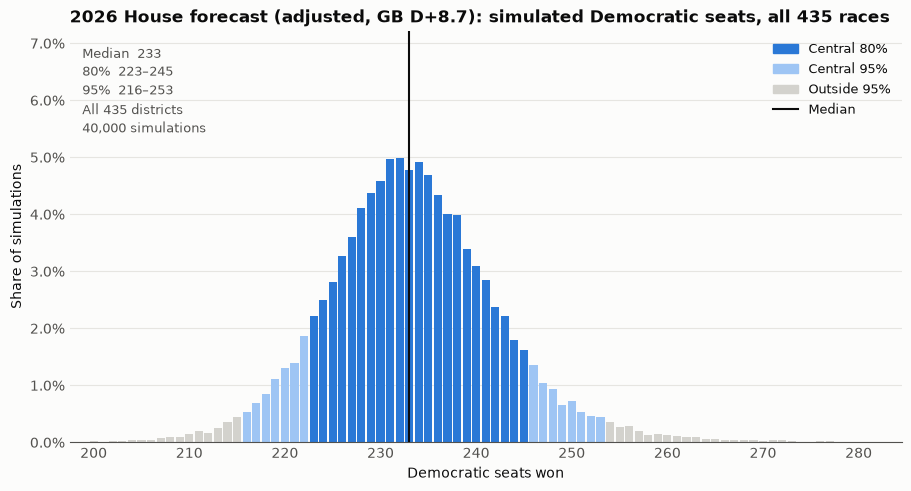

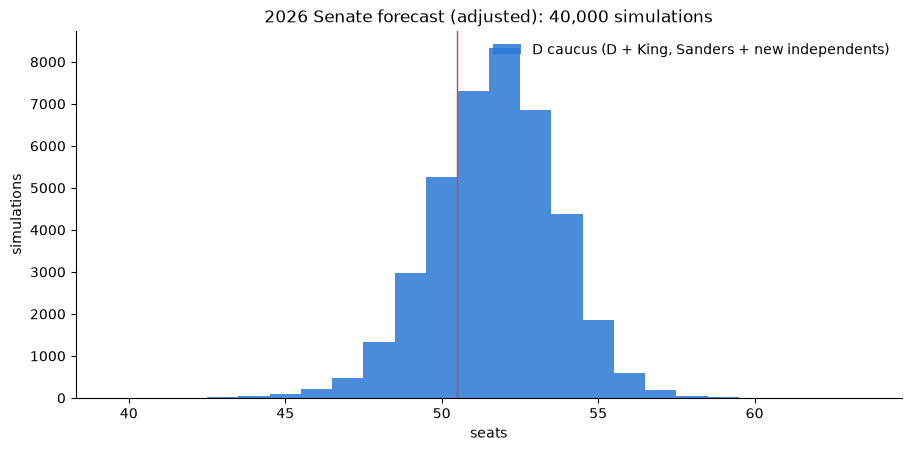

In [9]:
fig, ax = simulation.plot_seat_distribution(
    house_adjusted.draws.seats(simulation.DEM),
    year=2026,
    actual_seats=None,
    panel_size=house_forecast.HOUSE_SEATS,
    house_size=house_forecast.HOUSE_SEATS,
    title=f"2026 House forecast (adjusted, GB D{house_adjusted.generic_ballot:+.1f}): simulated Democratic seats, all 435 races",
)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
chamber.plot_seat_distribution(senate_adjusted.counts, ax, independents_with_dem=True,
                               title=f"2026 Senate forecast (adjusted): {senate_forecast.N_SIMS:,} simulations")
plt.show()

## 4. Every race: ratings and probabilities

The adjusted forecast, which is the submission. A race's rating comes from the predicted side's win probability, with the thresholds set in the settings cell. Within each group, races are sorted most Democratic first.

| column | meaning |
|---|---|
| `type` | House `race_type` (`dr` = D vs R; `dr_rcv`, `dr_jungle`, ...), Senate `seat_type` |
| `dem_candidate`, `gop_candidate` | each side's candidate. In Louisiana's all-candidate races it is the party's FEC model slot, the candidate Stage 1 simulated; Kiley (CA-6) is marked (I); in the Senate's independent-only races, `dem_candidate` is the independent |
| `margin_model` | the model's D − R two-party margin, in points (House Stage 1; Senate blend) |
| `margin_adjustment` | your adjustment (section 1) |
| `p_dem` | the share of simulations the Democrat wins |
| `dem_2p_norm`, `gop_2p_norm` | the two-party vote shares the adjusted margin implies: 50 ± (margin_model + margin_adjustment) / 2 |

In NE, ID and SD (`independent_only`), the margin is the independent's over the Republican. There `p_other` is the independent's win probability and `dem_2p_norm` is the independent's share.

In [10]:
adjusted = races["adjusted"]
display(Markdown(report.threshold_line(RATING_THRESHOLDS)))
report.rating_counts(adjusted)

Toss-up < 60% · Lean 60–75% · Likely 75–95% · Safe ≥ 95% (the predicted side's win probability)

rating,Safe D,Likely D,Lean D,Toss-up,Lean R,Likely R,Safe R
chamber,,,,,,,
House,204,16,7,9,9,30,160
Senate,11,4,3,2,0,3,12


### House

In [11]:
house_ratings = adjusted.loc[adjusted["chamber"] == "House", "rating"].value_counts()
display(Markdown(report.threshold_line(RATING_THRESHOLDS)))
display(Markdown(f"**House Safe D: {house_ratings.get('Safe D', 0)} · Safe R: {house_ratings.get('Safe R', 0)}**"))

Toss-up < 60% · Lean 60–75% · Likely 75–95% · Safe ≥ 95% (the predicted side's win probability)

**House Safe D: 204 · Safe R: 160**

In [12]:
table = report.rating_table(adjusted, chamber="House", rating="Toss-up", columns=report.RATING_GROUP_COLUMNS)
display(Markdown(f"**House Toss-up: {len(table)} races**"))
table.round(3)

**House Toss-up: 9 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm
0,WI-03,dr,Rebecca Cooke,Derrick Van Orden,1.297,0.0,0.586,50.648,49.352
1,TX-15,dr,Bobby Pulido,Monica De La Cruz,-7.022,8.0,0.567,50.489,49.511
2,VA-01,dr,Shannon Taylor,Rob Wittman,-0.061,0.0,0.496,49.970,50.030
3,TX-35,dr,Johnny Garcia,Carlos De La Cruz,-0.083,0.0,0.494,49.958,50.042
4,FL-22,dr,Pia Dandiya,Casey Askar,-0.426,0.0,0.472,49.787,50.213
5,PA-08,dr,Paige Cognetti,Rob Bresnahan,-0.431,0.0,0.470,49.784,50.216
6,WI-01,dr,Mitchell Berman,Bryan Steil,-0.616,0.0,0.458,49.692,50.308
7,IA-02,dr,Lindsay James,Joe Mitchell,-0.635,0.0,0.456,49.683,50.317
8,ME-02,dr_rcv,Matthew Dunlap,Paul LePage,-1.021,0.0,0.430,49.490,50.510


In [13]:
table = report.rating_table(adjusted, chamber="House", rating="Lean D", columns=report.RATING_GROUP_COLUMNS)
display(Markdown(f"**House Lean D: {len(table)} races**"))
table.round(3)

**House Lean D: 7 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm
0,PA-10,dr,Janelle Stelson,Scott Perry,3.822,0.0,0.745,51.911,48.089
1,PA-07,dr,Bob Brooks,Ryan Mackenzie,2.948,0.0,0.695,51.474,48.526
2,OH-07,dr,Brian Poindexter,Max Miller,-5.092,8.0,0.694,51.454,48.546
3,MI-10,dr,Christina Hines,Mike Bouchard Jr.,2.867,0.0,0.692,51.433,48.567
4,IA-01,dr,Christina Bohannan,Mariannette Miller-Meeks,2.427,0.0,0.664,51.213,48.787
5,NC-01,dr,Don Davis,Laurie Buckhout,1.929,0.0,0.634,50.965,49.035
6,PA-01,dr,Bob Harvie,Brian Fitzpatrick,1.612,0.0,0.613,50.806,49.194


In [14]:
table = report.rating_table(adjusted, chamber="House", rating="Lean R", columns=report.RATING_GROUP_COLUMNS)
display(Markdown(f"**House Lean R: {len(table)} races**"))
table.round(3)

**House Lean R: 9 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm
0,MI-04,dr,Sean McCann,Bill Huizenga,-1.457,0.0,0.395,49.272,50.728
1,AL-02,dr,Shomari Figures,Rhett Marques,-1.561,0.0,0.395,49.220,50.780
2,CO-03,dr,Dwayne Romero,Jeff Hurd,-1.868,0.0,0.369,49.066,50.934
3,MT-01,dr,Sam Forstag,Aaron Flint,-2.587,0.0,0.326,48.707,51.293
4,FL-09,dr,Darren Soto,Dan Green,-2.574,0.0,0.326,48.713,51.287
5,NY-01,dr,Chris Gallant,Nick LaLota,-2.725,0.0,0.323,48.637,51.363
6,MO-02,dr,Fred Wellman,Ann Wagner,-2.765,0.0,0.315,48.617,51.383
7,NC-11,dr,Jamie Ager,Jennifer Balkcom,-3.298,0.0,0.285,48.351,51.649
8,SC-01,dr,Nancy Lacore,Jenny Costa Honeycutt,-3.299,0.0,0.284,48.350,51.650


In [15]:
table = report.rating_table(adjusted, chamber="House", rating="Likely D", columns=report.RATING_GROUP_COLUMNS)
display(Markdown(f"**House Likely D: {len(table)} races**"))
table.round(3)

**House Likely D: 16 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm
0,WA-03,dr,Marie Gluesenkamp Perez,John Braun,10.195,0.0,0.948,55.098,44.902
1,OH-01,dr,Greg Landsman,Eric Conroy,9.360,0.0,0.938,54.680,45.320
2,TX-28,dr,Henry Cuellar,Tano Tijerina,9.269,0.0,0.934,54.634,45.366
3,AZ-01,dr,Amish Shah,Jay Feely,7.601,0.0,0.896,53.801,46.199
4,NY-17,dr,Cait Conley,Mike Lawler,6.855,0.0,0.876,53.428,46.572
5,AZ-06,dr,JoAnna Mendoza,Juan Ciscomani,6.812,0.0,0.876,53.406,46.594
6,VA-02,dr,Elaine Luria,Jen Kiggans,6.134,0.0,0.849,53.067,46.933
7,CA-22,dr,Randy Villegas,David Valadao,6.129,0.0,0.849,53.065,46.935
8,OH-09,dr,Marcy Kaptur,Derek Merrin,5.180,0.0,0.816,52.590,47.410
9,TX-34,dr,Vicente Gonzalez,Eric Flores,5.033,0.0,0.805,52.517,47.483


In [16]:
table = report.rating_table(adjusted, chamber="House", rating="Likely R", columns=report.RATING_GROUP_COLUMNS)
display(Markdown(f"**House Likely R: {len(table)} races**"))
table.round(3)

**House Likely R: 30 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,dem_2p_norm,gop_2p_norm
0,FL-13,dr,Leela Gray,Anna Paulina Luna,-4.101,0.0,0.241,47.949,52.051
1,FL-07,dr,Bale Dalton,Ryan Elijah,-4.319,0.0,0.227,47.840,52.160
2,FL-16,dr,Kelly Kirschner,Sydney Gruters,-4.446,0.0,0.223,47.777,52.223
3,OH-15,dr,Don Leonard,Mike Carey,-5.494,0.0,0.172,47.253,52.747
4,CO-05,dr,Jessica Killin,Jeff Crank,-5.545,0.0,0.171,47.228,52.772
5,NV-02,dr,Teresa Benitez-Thompson,David Flippo,-6.065,0.0,0.153,46.968,53.032
6,KY-06,dr,Zach Dembo,Ralph Alvarado,-6.190,0.0,0.147,46.905,53.095
7,AZ-02,dr,Jonathan Nez,Eli Crane,-6.152,0.0,0.147,46.924,53.076
8,AK-AL,dr_rcv,Eric Hafner,Nick Begich III,-6.777,0.0,0.125,46.611,53.389
9,MN-01,dr,Jake Johnson,Brad Finstad,-6.753,0.0,0.123,46.623,53.377


### Senate

In [17]:
SENATE_COLUMNS = ["race_id", "race_type", "dem_candidate", "gop_candidate", "margin_model", "margin_adjustment",
                  "p_dem", "p_other", "dem_2p_norm", "gop_2p_norm"]
senate_ratings = adjusted.loc[adjusted["chamber"] == "Senate", "rating"].value_counts()
independent = {r: n for r, n in senate_ratings.items() if r.endswith(" I")}  # an independent favored: none so far
display(Markdown(report.threshold_line(RATING_THRESHOLDS)))
display(Markdown(f"**Senate Safe D: {senate_ratings.get('Safe D', 0)} · Safe R: {senate_ratings.get('Safe R', 0)}**"
                 + (f" · independent favored: {independent}" if independent else "")))

Toss-up < 60% · Lean 60–75% · Likely 75–95% · Safe ≥ 95% (the predicted side's win probability)

**Senate Safe D: 11 · Safe R: 12**

In [18]:
table = report.rating_table(adjusted, chamber="Senate", rating="Toss-up", columns=SENATE_COLUMNS)
display(Markdown(f"**Senate Toss-up: {len(table)} races**"))
table.round(3)

**Senate Toss-up: 2 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,p_other,dem_2p_norm,gop_2p_norm
0,KS-SEN,dem_nominee,Adam Hamilton,Roger Marshall,-0.532,0.0,0.462,0.0,49.734,50.266
1,IA-SEN,dem_nominee,Josh Turek,Ashley Hinson,-1.104,0.0,0.426,0.0,49.448,50.552


In [19]:
table = report.rating_table(adjusted, chamber="Senate", rating="Lean D", columns=SENATE_COLUMNS)
display(Markdown(f"**Senate Lean D: {len(table)} races**"))
table.round(3)

**Senate Lean D: 3 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,p_other,dem_2p_norm,gop_2p_norm
0,AK-SEN,dem_nominee,Mary Peltola,Dan S. Sullivan,-0.629,2.5,0.626,0.0,50.936,49.064
1,OH-SEN,dem_nominee,Sherrod Brown,Jon Husted,1.668,0.0,0.615,0.0,50.834,49.166
2,TX-SEN,dem_nominee,James Talarico,Ken Paxton,1.631,0.0,0.608,0.0,50.816,49.184


In [20]:
table = report.rating_table(adjusted, chamber="Senate", rating="Lean R", columns=SENATE_COLUMNS)
display(Markdown(f"**Senate Lean R: {len(table)} races**"))
table.round(3)

**Senate Lean R: 0 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,p_other,dem_2p_norm,gop_2p_norm


In [21]:
table = report.rating_table(adjusted, chamber="Senate", rating="Likely D", columns=SENATE_COLUMNS)
display(Markdown(f"**Senate Likely D: {len(table)} races**"))
table.round(3)

**Senate Likely D: 4 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,p_other,dem_2p_norm,gop_2p_norm
0,GA-SEN,dem_nominee,Jon Ossoff,Mike Collins,10.380,0.0,0.945,0.0,55.190,44.810
1,NC-SEN,dem_nominee,Roy Cooper,Michael Whatley,9.948,0.0,0.940,0.0,54.974,45.026
2,ME-SEN,dem_nominee,Troy Jackson,Susan Collins,8.010,0.0,0.901,0.0,54.005,45.995
3,MI-SEN,dem_nominee,Abdul El-Sayed,Mike Rogers,6.980,0.0,0.871,0.0,53.490,46.510


In [22]:
table = report.rating_table(adjusted, chamber="Senate", rating="Likely R", columns=SENATE_COLUMNS)
display(Markdown(f"**Senate Likely R: {len(table)} races**"))
table.round(3)

**Senate Likely R: 3 races**

,race_id,type,dem_candidate,gop_candidate,margin_model,margin_adjustment,p_dem,p_other,dem_2p_norm,gop_2p_norm
0,FL-SEN,dem_nominee,Angie Nixon,Ashley Moody,-5.465,0.0,0.180,0.000,47.268,52.732
1,SC-SEN,dem_nominee,Annie Andrews,Darline Graham,-9.239,0.0,0.075,0.000,45.380,54.620
2,NE-SEN,independent_only,Dan Osborn (I),Pete Ricketts,-8.500,0.0,0.000,0.091,45.750,54.250


## 5. Same-party top-two races

California's top-two primary left nine D-vs-D or R-vs-R races: CA-4, 7, 11, 12, 14, 29, 34, 37 and 40. The party is certain, so these are Safe for it, and neither the generic-ballot shift nor the margin adjustments touch them. Which finalist wins comes from `simulation.TopTwoSameParty` (`src/house/simulation/top_two.py`):

- **The blend:** three predictions of the June leader's November margin over the runner-up: the June primary, fundraising, and a poll where one exists. Weighted 60/30/10 with a poll, 60/40 without.
- **Uncertainty:** the SD widens with the share of June voters who backed neither finalist (`uncommitted_share`).
- **The pick:** the finalist with p ≥ 0.5 is named. The submission's `win_probability` for these races is that candidate's p, not the party's.
- **Set by hand:** there is no training data, so the weights and SDs are the `TOP_TWO_*` settings in `src/house/forecast.py`. The inputs are in `data/processed/house/toptwosameparty.csv`.

In [23]:
display(pd.Series({"weights with a poll": house_forecast.TOP_TWO_WEIGHTS_WITH_POLL,
                   "weights without a poll": house_forecast.TOP_TWO_WEIGHTS_NO_POLL,
                   "points per log fundraising ratio": house_forecast.TOP_TWO_POINTS_PER_LOG,
                   "base SD (points)": house_forecast.TOP_TWO_BASE_SD,
                   "split SD": house_forecast.TOP_TWO_SPLIT_SD}, name="setting").to_frame())

top_two = house_inputs.top_two.assign(race_id=[simulation.race_id(s, d) for s, d in
                                               zip(house_inputs.top_two["state"], house_inputs.top_two["district"])])
picked = house_adjusted.table.merge(top_two, on=KEY, validate="one_to_one")
favorite = picked["leader"].where(picked["p_leader"] >= 0.5, picked["runner_up"])
assert (picked["predicted_candidate"] == favorite).all() and len(picked) == len(top_two)  # the forecast names them
submitted = adjusted.set_index("race_id")[["candidate_name", "win_probability"]]
top_two[["race_id", "leader", "runner_up", "margin_primary", "margin_fundraising", "margin_poll", "weights",
         "uncommitted_share", "mean", "sd", "interval_80_low", "interval_80_high", "p_leader", "p_runner_up"]].join(
    submitted, on="race_id").round(2)

,setting
weights with a poll,"{'primary': 0.6, 'fundraising': 0.3, 'poll': 0.1}"
weights without a poll,"{'primary': 0.6, 'fundraising': 0.4}"
points per log fundraising ratio,4.46
base SD (points),8.0
split SD,0.15


,race_id,leader,runner_up,margin_primary,margin_fundraising,margin_poll,weights,uncommitted_share,mean,sd,interval_80_low,interval_80_high,p_leader,p_runner_up,candidate_name,win_probability
0,CA-04,Mike Thompson,Eric Jones,29.65,-0.35,NaN,"primary 0.6, fundraising 0.4",36.80,17.65,13.63,2.06,33.24,0.92,0.08,Mike Thompson,0.92
1,CA-07,Mai Vang,Doris Matsui,3.55,1.81,-11.36,"primary 0.6, fundraising 0.3, poll 0.1",39.68,1.54,14.34,-14.86,17.94,0.55,0.45,Mai Vang,0.55
2,CA-11,Scott Wiener,Connie Chan,15.64,4.24,7.37,"primary 0.6, fundraising 0.3, poll 0.1",29.58,11.39,11.95,-2.27,25.05,0.86,0.14,Scott Wiener,0.86
3,CA-12,Lateefah Simon,Jamie Joyce,68.75,13.28,NaN,"primary 0.6, fundraising 0.4",0.15,46.56,8.00,37.41,55.71,1.00,0.00,Lateefah Simon,1.00
4,CA-14,Aisha Wahab,Melissa Hernandez,38.06,-3.37,NaN,"primary 0.6, fundraising 0.4",44.54,21.48,15.57,3.68,39.29,0.93,0.07,Aisha Wahab,0.93
5,CA-29,Luz Rivas,Angelica Dueñas,34.37,7.93,NaN,"primary 0.6, fundraising 0.4",24.02,23.79,10.77,11.48,36.10,0.98,0.02,Luz Rivas,0.98
6,CA-34,Jimmy Gomez,Angela Gonzales-Torres,19.94,2.08,-6.25,"primary 0.6, fundraising 0.3, poll 0.1",23.32,11.96,10.63,-0.19,24.11,0.90,0.10,Jimmy Gomez,0.90
7,CA-37,Sydney Kamlager-Dove,Samantha Mota,65.08,23.90,NaN,"primary 0.6, fundraising 0.4",33.15,48.61,12.76,34.02,63.20,1.00,0.00,Sydney Kamlager-Dove,1.00
8,CA-40,Ken Calvert,Young Kim,25.69,-3.36,NaN,"primary 0.6, fundraising 0.4",44.48,14.07,15.56,-3.71,31.86,0.85,0.15,Ken Calvert,0.85


## 6. What the adjustments change

Every adjusted race, model beside adjusted, plus any other race whose rating changed. Only the adjusted races' margins move, but the national and state draws are shared, so seat totals move too (section 3).

In [24]:
comparison = report.compare(races, ["margin", "p_dem", "p_other", "predicted_winner_party", "rating"])
touched = adjusted.set_index("race_id")["margin_adjustment"].ne(0) | report.changed(races, "model", "rating")
display(Markdown(f"**{int(touched.sum())} races**"))
comparison[touched].round(3)

**3 races**

margin           p_dem          p_other          predicted_winner_party             rating         
         model adjusted  model adjusted   model adjusted                  model adjusted     model adjusted
race_id                                                                                                    
AK-SEN  -0.629    1.871  0.458    0.626     0.0      0.0                      R        D   Toss-up   Lean D
OH-07   -5.092    2.908  0.190    0.694     0.0      0.0                      R        D  Likely R   Lean D
TX-15   -7.022    0.978  0.118    0.567     0.0      0.0                      R        D  Likely R  Toss-up

## 7. Generic-ballot shifts

The adjusted forecast rerun with 2026's generic ballot moved by each of `GB_SHIFTS`, using the same draws (the method is in `notebooks/scenarios/generic_ballot_shift.ipynb` and `src/congress/adjustments.py`).
- **House:** a race moves by Stage 1's own pass-through, about 0.66 points per point of generic ballot.
- **Senate:** only the fundamentals move. A polled race moves by the polling-case fundamentals weight times Stage 1's coefficient, and an unpolled one by the no-polling weight. The three independent-vs-R races don't move.
- **Only the input moves.** If the generic ballot were really that far off, the Senate polls would likely be wrong in the same direction. This doesn't model that.

**How likely each shift is.** The generic-ballot outcomes need no separate distribution, because the Monte Carlo already draws one. Every simulation draws a national error (a Student-t with ν = 5, House SD 2.35 margin points), estimated from how far the national environment missed in 2018–2024 *given* the election-eve generic ballot. That includes generic-ballot polling misses. In generic-ballot points it is that SD over the House pass-through, about 3.5 points.
- **So the shifts are stress tests, not extra weights.** Each one asks "what if the generic ballot input itself were off by x", with the national error still drawn inside it.
- **Mixing the shifted runs with weights would count the same national miss twice.** The table below gives each shift's tail probability under the model's own national error, to show how extreme it is.

In [25]:
house_runs, senate_runs = generic_ballot.scenario_runs(
    GB_SHIFTS,
    house_inputs=house_inputs,
    senate_inputs=senate_inputs,
    senate_weights=SENATE_WEIGHTS,
    house_adjustments=house_adjustments,
    senate_adjustments=senate_adjustments,
    baseline="adjusted",
)  # the adjusted forecast and each shift, most Republican first
pd.testing.assert_frame_equal(house_runs["adjusted"].track, house_adjusted.track)
SCENARIOS = list(house_runs)
for name in GB_SHIFTS:
    races[name] = report.race_table(house_runs[name], senate_runs[name], template, RATING_THRESHOLDS)
SHIFT_COLORS = {-4.0: "#a51c1c", -2.0: "#e07b7b", 2.0: "#7fb0ea", 4.0: "#1f5fbf"}
SCENARIO_COLORS = {name: "#222" if name == "adjusted" else SHIFT_COLORS.get(GB_SHIFTS[name], "#888")
                   for name in SCENARIOS}

shift_chambers = report.chamber_summary(house_runs, senate_runs, baseline="adjusted")
shift_chambers.T

,R+4,R+2,adjusted,D+2,D+4
generic ballot (D - R),4.7,6.7,8.7,10.7,12.7
House: mean race shift,-2.658659,-1.32933,0.0,1.32933,2.658659
House: median D seats,224.0,229.0,233.0,238.0,243.0
House: D seats 10%-90%,214–235,219–240,223–245,227–250,231–256
House: P(D 218+),0.816575,0.91915,0.966275,0.985875,0.993775
House: races called D,224,227,229,236,242
Senate: mean race shift (D nominees),-1.847776,-0.923888,0.0,0.923888,1.847776
Senate: median D-caucus seats,51.0,51.0,52.0,52.0,52.0
Senate: D-caucus seats 10%-90%,48–54,49–54,49–54,50–54,50–55
Senate: P(D control),0.613025,0.679325,0.74015,0.794425,0.840925


In [26]:
# Where each shift sits in the model's own national-error distribution (House: t(nu) x the national scale)
national_scale = house_inputs.error_scale["national"]
pass_through = {name: shift_chambers.loc[name, "House: mean race shift"] / shift for name, shift in GB_SHIFTS.items()}
pd.DataFrame({
    "generic ballot (D - R)": {name: house_runs[name].generic_ballot for name in GB_SHIFTS},
    "House race shift (points)": {name: shift_chambers.loc[name, "House: mean race shift"] for name in GB_SHIFTS},
    "points per GB point": pass_through,
    "P(national miss at least this far, this direction)": {
        name: stats.t.sf(abs(shift_chambers.loc[name, "House: mean race shift"]) / national_scale, house_forecast.NU)
        for name in GB_SHIFTS},
}).round(3)

,generic ballot (D - R),House race shift (points),points per GB point,"P(national miss at least this far, this direction)"
R+4,4.7,-2.659,0.665,0.105
R+2,6.7,-1.329,0.665,0.252
D+2,10.7,1.329,0.665,0.252
D+4,12.7,2.659,0.665,0.105


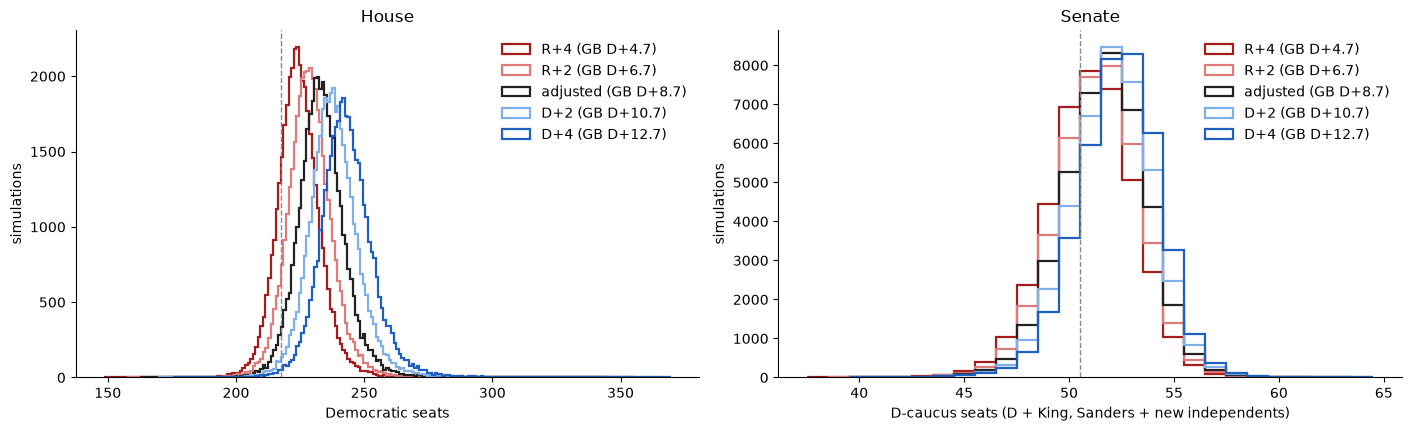

rating            Safe D  Likely D  Lean D  Toss-up  Lean R  Likely R  Safe R
scenario chamber                                                             
R+4      House       198        12       9        9       8        21     178
         Senate       10         5       0        3       2         2      13
R+2      House       201        12      11        7       8        28     168
         Senate       10         5       0        4       1         3      12
adjusted House       204        16       7        9       9        30     160
         Senate       11         4       3        2       0         3      12
D+2      House       207        17       5       13       6        33     154
         Senate       12         3       3        2       0         3      12
D+4      House       208        20       8       10       7        40     142
         Senate       13         2       3        2       0         3      12

In [27]:
def plot_chambers(house_runs, senate_runs, colors):
    _fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
    for name, h in house_runs.items():
        seats = h.draws.seats(simulation.DEM)
        axes[0].hist(seats, bins=np.arange(seats.min() - 0.5, seats.max() + 1.5), histtype="step", lw=1.6,
                     color=colors[name], label=f"{name} (GB D{h.generic_ballot:+.1f})")
    axes[0].axvline(report.HOUSE_MAJORITY - 0.5, color="#888", lw=1, ls="--")
    axes[0].set(xlabel="Democratic seats", ylabel="simulations", title="House")
    for name, s in senate_runs.items():
        seats = report.senate_dem_caucus(s.counts)
        axes[1].hist(seats, bins=np.arange(seats.min() - 0.5, seats.max() + 1.5), histtype="step", lw=1.6,
                     color=colors[name], label=f"{name} (GB D{s.generic_ballot:+.1f})")
    axes[1].axvline(50.5, color="#888", lw=1, ls="--")
    axes[1].set(xlabel="D-caucus seats (D + King, Sanders + new independents)", ylabel="simulations", title="Senate")
    for ax in axes:
        ax.legend(frameon=False)
        ax.spines[["top", "right"]].set_visible(False)
    plt.show()


plot_chambers(house_runs, senate_runs, colors=SCENARIO_COLORS)
display(pd.concat({name: report.rating_counts(races[name]) for name in SCENARIOS}, names=["scenario"]).fillna(0)
        .astype(int))

In [28]:
# Every race whose rating changes under some shift: probability and rating per scenario
shifted = {name: races[name] for name in SCENARIOS}
moved = report.changed(shifted, "adjusted", "rating")
display(Markdown(f"**{int(moved.sum())} races change rating**; their predicted winners:"))
display(report.compare(shifted, ["p_dem", "p_other", "rating"])[moved].round(3))
report.flipped_races({name: t[["race_id", "predicted_winner_party", "candidate_name", "win_probability"]]
                      for name, t in shifted.items()}, baseline="adjusted").round(3)

**98 races change rating**; their predicted winners:

p_dem                               p_other                            rating                                        
           R+4    R+2 adjusted    D+2    D+4     R+4  R+2 adjusted  D+2  D+4       R+4       R+2  adjusted       D+2       D+4
race_id                                                                                                                       
AK-SEN   0.544  0.586    0.626  0.663  0.699     0.0  0.0      0.0  0.0  0.0   Toss-up   Toss-up    Lean D    Lean D    Lean D
GA-SEN   0.926  0.936    0.945  0.952  0.959     0.0  0.0      0.0  0.0  0.0  Likely D  Likely D  Likely D    Safe D    Safe D
IA-SEN   0.347  0.385    0.426  0.467  0.512     0.0  0.0      0.0  0.0  0.0    Lean R    Lean R   Toss-up   Toss-up   Toss-up
KS-SEN   0.382  0.421    0.462  0.505  0.545     0.0  0.0      0.0  0.0  0.0    Lean R   Toss-up   Toss-up   Toss-up   Toss-up
NC-SEN   0.917  0.929    0.940  0.948  0.956     0.0  0.0      0.0  0.0  0.0  Likely D  Likely D  Likely D  Likely D    Safe D
NH-SEN   0.931  0.941    0.950  0.957  0.964     0.0  0.0      0.0  0.0  0.0  Likely D  Likely D    Safe D    Safe D    Safe D
OH-SEN   0.534  0.574    0.615  0.655  0.691     0.0  0.0      0.0  0.0  0.0   Toss-up   Toss-up    Lean D    Lean D    Lean D
SC-SEN   0.042  0.056    0.075  0.097  0.124     0.0  0.0      0.0  0.0  0.0    Safe R  Likely R  Likely R  Likely R  Likely R
TX-SEN   0.525  0.568    0.608  0.648  0.685     0.0  0.0      0.0  0.0  0.0   Toss-up   Toss-up    Lean D    Lean D    Lean D
AL-02    0.238  0.310    0.395  0.485  0.576     0.0  0.0      0.0  0.0  0.0  Likely R    Lean R    Lean R   Toss-up   Toss-up
AR-02    0.022  0.033    0.048  0.070  0.100     0.0  0.0      0.0  0.0  0.0    Safe R    Safe R    Safe R  Likely R  Likely R
AZ-01    0.802  0.854    0.896  0.927  0.950     0.0  0.0      0.0  0.0  0.0  Likely D  Likely D  Likely D  Likely D    Safe D
AZ-02    0.072  0.105    0.147  0.202  0.272     0.0  0.0      0.0  0.0  0.0  Likely R  Likely R  Likely R  Likely R    Lean R
AZ-05    0.015  0.023    0.032  0.048  0.071     0.0  0.0      0.0  0.0  0.0    Safe R    Safe R    Safe R    Safe R  Likely R
AZ-08    0.036  0.053    0.077  0.108  0.152     0.0  0.0      0.0  0.0  0.0    Safe R  Likely R  Likely R  Likely R  Likely R
CA-22    0.725  0.793    0.849  0.893  0.925     0.0  0.0      0.0  0.0  0.0    Lean D  Likely D  Likely D  Likely D  Likely D
CA-48    0.932  0.953    0.968  0.978  0.985     0.0  0.0      0.0  0.0  0.0  Likely D    Safe D    Safe D    Safe D    Safe D
CO-03    0.215  0.288    0.369  0.459  0.551     0.0  0.0      0.0  0.0  0.0  Likely R    Lean R    Lean R   Toss-up   Toss-up
CO-04    0.040  0.059    0.084  0.119  0.164     0.0  0.0      0.0  0.0  0.0    Safe R  Likely R  Likely R  Likely R  Likely R
CO-05    0.086  0.123    0.171  0.231  0.305     0.0  0.0      0.0  0.0  0.0  Likely R  Likely R  Likely R  Likely R    Lean R
CO-08    0.631  0.713    0.783  0.842  0.888     0.0  0.0      0.0  0.0  0.0    Lean D    Lean D  Likely D  Likely D  Likely D
FL-02    0.039  0.057    0.084  0.119  0.164     0.0  0.0      0.0  0.0  0.0    Safe R  Likely R  Likely R  Likely R  Likely R
FL-07    0.118  0.167    0.227  0.300  0.385     0.0  0.0      0.0  0.0  0.0  Likely R  Likely R  Likely R    Lean R    Lean R
FL-08    0.014  0.020    0.030  0.044  0.063     0.0  0.0      0.0  0.0  0.0    Safe R    Safe R    Safe R    Safe R  Likely R
FL-09    0.185  0.249    0.326  0.415  0.508     0.0  0.0      0.0  0.0  0.0  Likely R  Likely R    Lean R   Toss-up   Toss-up
FL-11    0.042  0.063    0.090  0.128  0.179     0.0  0.0      0.0  0.0  0.0    Safe R  Likely R  Likely R  Likely R  Likely R
FL-12    0.013  0.019    0.028  0.041  0.059     0.0  0.0      0.0  0.0  0.0    Safe R    Safe R    Safe R    Safe R  Likely R
FL-13    0.129  0.179    0.241  0.317  0.403     0.0  0.0      0.0  0.0  0.0  Likely R  Likely R  Likely R    Lean R   Toss-up
FL-14    0.650  0.732    0.798  0.853  0.894     0.0  0.0      0.0  0.0 

candidate_name                                                                                 predicted_winner_party                      win_probability                              
                              R+4                 R+2            adjusted                 D+2                 D+4                    R+4 R+2 adjusted D+2 D+4             R+4    R+2 adjusted    D+2    D+4
race_id                                                                                                                                                                                                    
IA-SEN              Ashley Hinson       Ashley Hinson       Ashley Hinson       Ashley Hinson          Josh Turek                      R   R        R   R   D           0.653  0.615    0.574  0.533  0.512
KS-SEN             Roger Marshall      Roger Marshall      Roger Marshall       Adam Hamilton       Adam Hamilton                      R   R        R   D   D           0.618  0.579    0.538  0.505  0.545
AL-02               Rhett Marques       Rhett Marques       Rhett Marques       Rhett Marques     Shomari Figures                      R   R        R   R   D           0.762  0.690    0.605  0.515  0.576
CO-03                   Jeff Hurd           Jeff Hurd           Jeff Hurd           Jeff Hurd       Dwayne Romero                      R   R        R   R   D           0.785  0.712    0.631  0.541  0.551
FL-09                   Dan Green           Dan Green           Dan Green           Dan Green         Darren Soto                      R   R        R   R   D           0.815  0.751    0.674  0.585  0.508
FL-22                 Casey Askar         Casey Askar         Casey Askar         Pia Dandiya         Pia Dandiya                      R   R        R   D   D           0.704  0.619    0.528  0.564  0.650
IA-01    Mariannette Miller-Meeks  Christina Bohannan  Christina Bohannan  Christina Bohannan  Christina Bohannan                      R   D        D   D   D           0.515  0.578    0.664  0.744  0.809
IA-02                Joe Mitchell        Joe Mitchell        Joe Mitchell       Lindsay James       Lindsay James                      R   R        R   D   D           0.718  0.635    0.544  0.548  0.637
ME-02                 Paul LePage         Paul LePage         Paul LePage      Matthew Dunlap      Matthew Dunlap                      R   R        R   D   D           0.736  0.659    0.570  0.521  0.610
MI-04               Bill Huizenga       Bill Huizenga       Bill Huizenga       Bill Huizenga         Sean McCann                      R   R        R   R   D           0.764  0.689    0.605  0.514  0.583
MT-01                 Aaron Flint         Aaron Flint         Aaron Flint         Aaron Flint         Sam Forstag                      R   R        R   R   D           0.817  0.751    0.674  0.589  0.502
NC-01             Laurie Buckhout           Don Davis           Don Davis           Don Davis           Don Davis                      R   D        D   D   D           0.547  0.546    0.634  0.715  0.785
NY-01                 Nick LaLota         Nick LaLota         Nick LaLota         Nick LaLota       Chris Gallant                      R   R        R   R   D           0.822  0.758    0.677  0.593  0.502
PA-01           Brian Fitzpatrick          Bob Harvie          Bob Harvie          Bob Harvie          Bob Harvie                      R   D        D   D   D           0.569  0.523    0.613  0.696  0.769
PA-08               Rob Bresnahan       Rob Bresnahan       Rob Bresnahan      Paige Cognetti      Paige Cognetti                      R   R        R   D   D           0.702  0.620    0.530  0.561  0.648
TX-15           Monica De La Cruz   Monica De La Cruz        Bobby Pulido        Bobby Pulido        Bobby Pulido                      R   R        D   D   D           0.613  0.524    0.567  0.652  0.732
TX-35           Carlos De La Cruz   Carlos De La Cruz   Carlos De La Cruz       Johnny Garcia       Johnny Garcia                      R   R   

## 8. Submission and exports

- **The submission** is the adjusted forecast at the actual generic ballot (no shift). `congress_track.write_submission` merges the two chambers into the template, validates every race, rounds to 6 decimals, and writes `data/processed/full_congress_track_2026.csv` and `data/processed/full congress track template.csv`.
- **`data/processed/forecast/races_2026.csv`:** every race in the adjusted forecast, plus `p_dem`, `p_other` and the rating under the model run and each shift.
- **`data/processed/forecast/chambers_2026.csv`:** the chamber summaries of every run.
- **`data/processed/forecast/gb_scenarios_2026.csv`:** every race's prediction in every generic-ballot scenario, one row per (scenario, race): the margin, `p_dem`, `p_gop`, `p_other`, the predicted winner and the rating.
- **Determinism:** rerunning the adjusted forecast must give identical track rows.

In [29]:
again_house = house_forecast.run(house_inputs, adjustments=house_adjustments)
again_senate = senate_forecast.run(senate_inputs, weights=SENATE_WEIGHTS, adjustments=senate_adjustments)
pd.testing.assert_frame_equal(again_house.track, house_adjusted.track)
pd.testing.assert_frame_equal(again_senate.track, senate_adjusted.track)
print("rerun gives identical House and Senate rows")

SUBMISSION_PATHS = (congress_track.OUTPUT_PATH, congress_track.SUBMISSION_PATH) if WRITE_SUBMISSION else ()
submission = congress_track.write_submission({"House": house_adjusted.track, "Senate": senate_adjusted.track},
                                             template=template, paths=SUBMISSION_PATHS)
for path in SUBMISSION_PATHS:
    print(f"-> {path.relative_to(ROOT)} ({len(submission)} rows)")
display(submission.groupby(["chamber", "predicted_winner_party"]).size().unstack(fill_value=0))

rerun gives identical House and Senate rows
-> data/processed/full_congress_track_2026.csv (470 rows)
-> data/processed/full congress track template.csv (470 rows)


predicted_winner_party,D,R
chamber,,
House,229,206
Senate,18,17


In [30]:
OUT_DIR = ROOT / "data/processed/forecast"
OUT_DIR.mkdir(parents=True, exist_ok=True)

export = adjusted.drop(columns="party_probability").copy()
for name, table in races.items():
    if name == "adjusted":
        continue
    other = table.set_index("race_id")
    for column in ["p_dem", "p_other", "rating"]:
        export[f"{column} ({name})"] = export["race_id"].map(other[column])
export = export.round(6)
export.to_csv(OUT_DIR / "races_2026.csv", index=False)

all_chambers = pd.concat([chambers, shift_chambers.drop(index="adjusted")]).rename_axis("run").reset_index()
all_chambers.round(6).to_csv(OUT_DIR / "chambers_2026.csv", index=False)
scenario_columns = ["race_id", "chamber", "race_type", "dem_candidate", "gop_candidate", "margin", "p_dem", "p_gop",
                    "p_other", "predicted_winner_party", "candidate_name", "win_probability", "rating"]
scenario_predictions = pd.concat(
    [races[name][scenario_columns].assign(scenario=name, gb_shift=GB_SHIFTS.get(name, 0.0),
                                          generic_ballot=house_runs[name].generic_ballot) for name in SCENARIOS],
    ignore_index=True)
scenario_predictions = scenario_predictions[["scenario", "gb_shift", "generic_ballot", *scenario_columns]].round(6)
scenario_predictions.to_csv(OUT_DIR / "gb_scenarios_2026.csv", index=False)
for filename in ["races_2026.csv", "chambers_2026.csv", "gb_scenarios_2026.csv"]:
    print(f"-> {(OUT_DIR / filename).relative_to(ROOT)}")

-> data/processed/forecast/races_2026.csv
-> data/processed/forecast/chambers_2026.csv
-> data/processed/forecast/gb_scenarios_2026.csv


## 9. Kalshi: the portfolio and its volatility

- **The portfolio** is sized on the main forecast: the submission above, priced against the latest **cached** Kalshi snapshot (`data/raw/kalshi/`; no API call), with `src/kalshi/run.py`'s settings. It is the toss-ups at quarter Kelly, which is exactly what `run.py` writes to `kelly_bets_2026.csv`.
- **Volatility:** the same bets are priced in every one of the 40,000 simulations (`src/kalshi/portfolio.py`). A bet pays $1 when its side wins and costs its price plus Kalshi's fee. Each simulation draws its own national error, which is the generic-ballot uncertainty, and the races move together through it, so the spread of portfolio profit across simulations is the volatility.
- **Stress tests:** the same bets and the same picks, in each generic-ballot scenario's simulations.
- **Worst case:** the stress scenario with the lowest expected profit, and the tails of the profit distribution.
- **Caveats:**
  - Everything is valued at the model's probabilities, so profit means "if the model is right."
  - House and Senate are simulated with independent national errors, so the combined spread understates how the two chambers' bets move together. The stress tests do move both together.
  - Fills are assumed at the quoted top of book, with no slippage.

In [31]:
events, kalshi_as_of = kalshi_run.load_events([])  # the latest cached snapshot; never the API
markets = odds.fill_party_from_candidates(odds.race_markets(events), pd.read_csv(kalshi_run.CANDIDATES_PATH))
markets = markets[markets["race_id"].isin(submission["race_id"])]
odds_table = odds.track_odds(submission, markets)
bets = optimizer.kelly_bets(optimizer.tossups(odds_table, low=kalshi_run.TOSSUP_LOW, high=kalshi_run.TOSSUP_HIGH),
                            markets, bankroll=kalshi_run.BANKROLL, kelly_fraction=kalshi_run.KELLY_FRACTION,
                            min_edge=kalshi_run.MIN_EDGE)
saved_bets = pd.read_csv(kalshi_run.OUT_DIR / "kelly_bets_2026.csv")
current = len(saved_bets) == len(bets) and np.allclose(saved_bets["expected_profit"], bets["expected_profit"])
display(Markdown(f"**{len(bets)} bets**, stake ${bets['stake'].sum():,.2f}, prices as of {kalshi_as_of}; "
                 f"`kelly_bets_2026.csv` is {'current' if current else 'STALE: rerun src/kalshi/run.py'}"))
bets[["race_id", "candidate", "side", "price", "cost", "belief", "edge", "contracts", "stake", "expected_profit"]].round(3)

Kalshi prices from the cached snapshot events_2026-11-03T2047Z.json (no API call)


**30 bets**, stake $786.95, prices as of 2026-11-03T2047Z; `kelly_bets_2026.csv` is current

,race_id,candidate,side,price,cost,belief,edge,contracts,stake,expected_profit
0,TX-23,Katy Padilla Stout,no,0.59,0.607,0.944,0.337,96,58.266,32.318
1,NC-13,Paul Barringer,no,0.60,0.617,0.944,0.327,41,25.289,13.418
2,CA-04,Eric Jones,no,0.57,0.587,0.922,0.335,1,0.587,0.335
3,NC-03,Raymond Smith Jr.,no,0.60,0.617,0.926,0.309,89,54.895,27.543
4,NJ-02,Jeff Van Drew,yes,0.53,0.547,0.913,0.365,100,54.744,36.546
5,KY-06,Ralph Alvarado,yes,0.41,0.427,0.853,0.426,118,50.378,50.252
6,NY-17,Cait Conley,yes,0.54,0.557,0.876,0.319,87,48.493,27.748
7,VA-05,Tom Perriello,no,0.59,0.607,0.883,0.276,4,2.428,1.103
8,CA-40,Young Kim,no,0.50,0.518,0.852,0.335,5,2.588,1.674
9,MN-01,Jake Johnson,no,0.60,0.617,0.877,0.260,74,45.643,19.220


In [32]:
# Each bet's profit in every simulation of every scenario, the picks fixed at the submission's
# (scenarios.generic_ballot.portfolio_risk, the same function src/kalshi/run.py uses)
risk, by_bet, profits = generic_ballot.portfolio_risk(bets, odds_table, submission, house_runs, senate_runs,
                                                      seed=house_forecast.SEED)
# The adjusted run's mean profit is the bets' expected profit (up to the same-party top-two candidate draws)
assert abs(profits["adjusted"].sum(axis=1).mean() - bets["expected_profit"].sum()) < 0.005 * bets["stake"].sum()
risk.round(3)

,generic ballot (D - R),expected profit,sd,P(loss),5th percentile,1st percentile,worst simulation,best simulation,stake,expected return on stake
R+4,4.7,802.250,248.121,0.005,355.046,116.036,-677.954,1249.046,786.954,1.019
R+2,6.7,703.379,269.934,0.011,231.046,-11.964,-681.954,1249.046,786.954,0.894
adjusted,8.7,590.797,286.297,0.025,103.996,-125.964,-681.954,1249.046,786.954,0.751
D+2,10.7,468.293,296.231,0.058,-18.954,-234.964,-693.954,1249.046,786.954,0.595
D+4,12.7,338.540,298.802,0.127,-141.954,-346.954,-693.954,1249.046,786.954,0.430


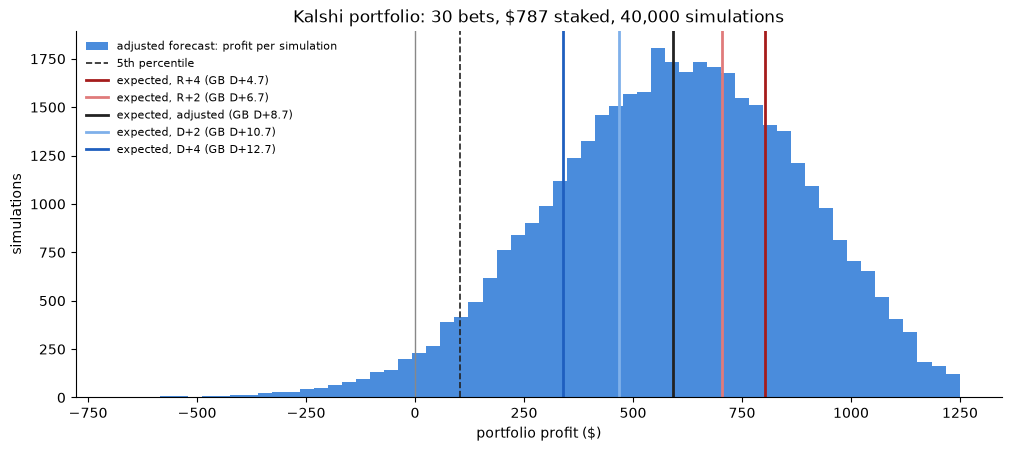

In [33]:
fig, ax = plt.subplots(figsize=(10, 4.4), layout="constrained")
total = profits["adjusted"].sum(axis=1)
ax.hist(total, bins=60, color="#2a78d6", alpha=0.85, label="adjusted forecast: profit per simulation")
ax.axvline(0, color="#888", lw=1)
ax.axvline(np.quantile(total, 0.05), color="#222", lw=1.2, ls="--", label="5th percentile")
for name in SCENARIOS:
    ax.axvline(risk.loc[name, "expected profit"], color=SCENARIO_COLORS[name], lw=2,
               label=f"expected, {name} (GB D{house_runs[name].generic_ballot:+.1f})")
ax.set(xlabel="portfolio profit ($)", ylabel="simulations",
       title=f"Kalshi portfolio: {len(bets)} bets, ${bets['stake'].sum():,.0f} staked, {len(total):,} simulations")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Worst case

The stress scenario where the portfolio does worst, then each bet's expected profit in every scenario. The bets that lose the most in the worst scenario are listed first.

In [34]:
worst = risk["expected profit"].idxmin()
row = risk.loc[worst]
display(Markdown(
    f"**Worst scenario: {worst}** (generic ballot D{row['generic ballot (D - R)']:+.1f}). "
    f"Expected profit **${row['expected profit']:,.0f}** on ${row['stake']:,.0f} staked; P(loss) {row['P(loss)']:.1%}; "
    f"5th percentile **${row['5th percentile']:,.0f}**; worst simulation **${row['worst simulation']:,.0f}**. "
    f"Across every scenario and simulation the worst is ${risk['worst simulation'].min():,.0f}, "
    f"and the most the portfolio can lose is its stake, ${bets['stake'].sum():,.0f}."))
by_bet.sort_values(worst).round(2)

**Worst scenario: D+4** (generic ballot D+12.7). Expected profit **$339** on $787 staked; P(loss) 12.7%; 5th percentile **$-142**; worst simulation **$-694**. Across every scenario and simulation the worst is $-694, and the most the portfolio can lose is its stake, $787.

,,,stake,R+4,R+2,adjusted,D+2,D+4
race_id,candidate,side,,,,,,
CO-03,Jeff Hurd,yes,11.15,4.56,3.10,1.46,-0.33,-2.18
AL-02,Rhett Marques,yes,15.60,8.78,6.47,3.78,0.88,-2.04
MO-02,Fred Wellman,no,10.65,3.34,2.28,1.00,-0.43,-2.00
FL-22,Casey Askar,yes,14.67,11.39,8.22,4.86,1.45,-1.74
WI-01,Bryan Steil,yes,4.57,1.84,1.08,0.31,-0.53,-1.33
IA-SEN,Ashley Hinson,yes,6.33,1.51,1.05,0.56,0.07,-0.47
SC-01,Nancy S. Lacore,no,25.18,13.66,11.00,7.77,4.10,-0.07
CA-04,Eric Jones,no,0.59,0.34,0.34,0.34,0.34,0.34
VA-05,Tom Perriello,no,2.43,1.34,1.24,1.10,0.92,0.69


In [35]:
for path in generic_ballot.write_portfolio_risk(risk, by_bet, kalshi_run.OUT_DIR):
    print(f"-> {path.relative_to(ROOT)}")

-> data/processed/kalshi/portfolio_risk_2026.csv
-> data/processed/kalshi/portfolio_stress_bets_2026.csv


## 10. Final predictions: `predictions/final_preds.csv`

One row per race, in the submission's order. Every number is the **submitted candidate's**, from the adjusted forecast (the submission), which uses only pre-election information.

| column | meaning |
|---|---|
| `race_id`, `chamber`, `predicted_winner_party`, `candidate_name` | the submission's row |
| `predicted_margin` | the candidate's predicted two-party margin over the runner-up, in points (positive: the candidate wins): the adjusted margin the Monte Carlo is drawn around (same-party top-two races: the top-two model's mean); blank for races decided by rule |
| `predicted_80_low`, `pred_80_high` | the 10th and 90th percentiles of the candidate's simulated two-party margin over the runner-up, in points (positive: the candidate wins). Same-party top-two races use the top-two model's 80% interval (section 5); races decided by rule have no simulated margin and are blank |
| `win_probability` | the submission's |
| `gen_ballot_less4`, `gen_ballot_plus4` | the candidate's win probability with the generic ballot 4 points less / more Democratic (section 7's R+4 and D+4 runs: D+4.7 and D+12.7); same-party top-two races don't depend on it |
| `polymarket_odd` | Polymarket's **current** probability for the candidate: the bid-ask midpoint (else the last trade), normalized within the race (`src/polymarket/odds.py`) |
| `polymarket_delta` | `win_probability` − `polymarket_odd`: positive when the model is more confident in the candidate than Polymarket |

**Polymarket is live, the model is not.** With `POLYMARKET_REFRESH = True` the prices are pulled when this cell runs, so on election night they already reflect early returns; the model's columns never do. The pull time is printed below and the raw pull is saved in `data/raw/polymarket/`. The assembly is `src/congress/predictions.py`.

In [36]:
polymarket_events, polymarket_as_of = polymarket_odds.load_events(refresh=POLYMARKET_REFRESH)
polymarket_markets = polymarket_odds.race_markets(polymarket_events)
same_party = {simulation.race_id(r.state, r.district) for r in house_adjusted.draws.races.itertuples(index=False)
              if r.treatment == "same_party"}
polymarket = polymarket_odds.track_odds(submission, polymarket_markets, same_party)

final_preds = predictions.final_predictions(submission, house_runs, senate_runs, house_inputs.top_two, polymarket)

# Checks: the draws reproduce the submitted probabilities, and every interval is ordered
baseline = predictions.shifted_win_probability(submission, house_adjusted, senate_adjusted)
assert np.allclose(final_preds["race_id"].map(baseline), final_preds["win_probability"], atol=1e-6)
assert final_preds["race_id"].equals(submission["race_id"])
intervals = final_preds.dropna(subset=["predicted_80_low"])
assert (intervals["predicted_80_low"] <= intervals["pred_80_high"]).all()
assert intervals["predicted_margin"].between(intervals["predicted_80_low"], intervals["pred_80_high"]).all()
assert final_preds["predicted_margin"].isna().equals(final_preds["predicted_80_low"].isna())

FINAL_PREDS_PATH.parent.mkdir(parents=True, exist_ok=True)
final_preds.round(6).to_csv(FINAL_PREDS_PATH, index=False)
unpriced = polymarket[polymarket["polymarket_odd"].isna()]
display(Markdown(
    f"-> `{FINAL_PREDS_PATH.relative_to(ROOT)}` ({len(final_preds)} rows). Polymarket prices as of **{polymarket_as_of}** "
    f"({'live pull' if POLYMARKET_REFRESH else 'cached pull'}): {int(final_preds['polymarket_odd'].notna().sum())} of "
    f"{len(final_preds)} races priced. Margin intervals for {len(intervals)} races; the other "
    f"{len(final_preds) - len(intervals)} are decided by rule."))
if len(unpriced):
    display(unpriced)
final_preds.round(3)

-> `predictions/final_preds.csv` (470 rows). Polymarket prices as of **2026-11-04T0055Z** (live pull): 470 of 470 races priced. Margin intervals for 461 races; the other 9 are decided by rule.

,race_id,chamber,predicted_winner_party,candidate_name,predicted_margin,predicted_80_low,pred_80_high,win_probability,gen_ballot_less4,gen_ballot_plus4,polymarket_odd,polymarket_delta
0,AK-SEN,Senate,D,Mary Peltola,1.871,-6.096,9.979,0.626,0.544,0.699,0.759,-0.133
1,AL-SEN,Senate,R,Barry Moore,23.637,15.577,31.662,0.998,0.998,0.996,0.977,0.020
2,AR-SEN,Senate,R,Tom Cotton,25.883,17.863,33.954,0.998,0.999,0.998,0.944,0.055
3,CO-SEN,Senate,D,John Hickenlooper,25.613,17.546,33.554,0.998,0.997,0.999,0.993,0.005
4,DE-SEN,Senate,D,Chris Coons,28.166,20.229,36.096,0.999,0.998,0.999,0.987,0.012
...,...,...,...,...,...,...,...,...,...,...,...,...
465,WI-07,House,R,Michael Alfonso,14.496,6.755,22.168,0.984,0.992,0.968,0.863,0.121
466,WI-08,House,R,Tony Wied,11.598,3.732,19.290,0.964,0.983,0.926,0.889,0.074
467,WV-01,House,R,Carol Miller,42.718,35.031,50.358,1.000,1.000,1.000,0.978,0.022
468,WV-02,House,R,Riley Moore,38.692,31.075,46.392,1.000,1.000,1.000,0.980,0.019


In [37]:
# Where the model and Polymarket disagree most (polymarket_delta: the candidate's probability, model minus Polymarket)
final_preds.reindex(final_preds["polymarket_delta"].abs().sort_values(ascending=False).index).head(20).round(3)

,race_id,chamber,predicted_winner_party,candidate_name,predicted_margin,predicted_80_low,pred_80_high,win_probability,gen_ballot_less4,gen_ballot_plus4,polymarket_odd,polymarket_delta
193,IN-05,House,R,Victoria Spartz,12.768,5.061,20.500,0.975,0.988,0.947,0.095,0.880
270,NC-03,House,R,Greg Murphy,8.928,1.158,16.593,0.926,0.965,0.853,0.079,0.847
280,NC-13,House,R,Brad Knott,9.881,2.148,17.512,0.944,0.974,0.886,0.184,0.760
207,KY-06,House,R,Ralph Alvarado,6.190,-1.454,13.804,0.853,0.928,0.728,0.095,0.758
89,CA-34,House,D,Jimmy Gomez,11.962,-0.187,24.111,0.897,0.897,0.897,0.202,0.695
342,OH-10,House,R,Mike Turner,8.179,0.480,15.826,0.913,0.957,0.825,0.230,0.683
278,NC-11,House,R,Jennifer Balkcom,3.298,-4.473,11.053,0.715,0.843,0.540,0.058,0.657
130,FL-09,House,R,Dan Green,2.574,-5.044,10.311,0.674,0.815,0.492,0.111,0.563
28,SC-SEN,Senate,R,Darline Graham,9.239,1.228,17.302,0.925,0.958,0.876,0.397,0.528
143,FL-22,House,R,Casey Askar,0.426,-7.348,8.220,0.528,0.704,0.350,0.025,0.503
